# 📈 DỰ BÁO DOANH SỐ TƯƠNG LAI (ADVANCED_MODEL.IPYNB)
**Dự án**: SMB Sales Analytics & Forecasting Platform  
**Mục tiêu**: Xây dựng mô hình Chuỗi thời gian (Time Series Forecasting) sử dụng thuật toán **Holt-Winters Exponential Smoothing** để dự báo doanh số các tháng tiếp theo.

## 1. Import Thư viện & Modules Dự án

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error

from src.pipeline import clean_and_transform_data
from src.model import prepare_time_series_data, train_forecast_model, forecast_future_sales

plt.style.use('seaborn-v0_8-whitegrid')
print('✅ Đã import thành công các module nâng cao!')


✅ Đã import thành công các module nâng cao!


## 2. Chuẩn bị Dữ liệu Lịch sử (Time Series Data Preparation)

In [2]:
data_file = os.path.join('data', 'dirty_cafe_sales.csv')
if os.path.exists(data_file):
    df_processed = clean_and_transform_data(data_file)
    print(f'✅ Xử lý hoàn tất {len(df_processed)} bản ghi.')
else:
    print('⚠️ File dirty_cafe_sales.csv chưa có.')
    df_processed = pd.DataFrame()

ts_data = prepare_time_series_data(df_processed, freq='ME')
ts_data.head()


✅ Xử lý hoàn tất 9540 bản ghi.


## 3. Trực quan hóa Chuỗi thời gian (Time Series Plot)

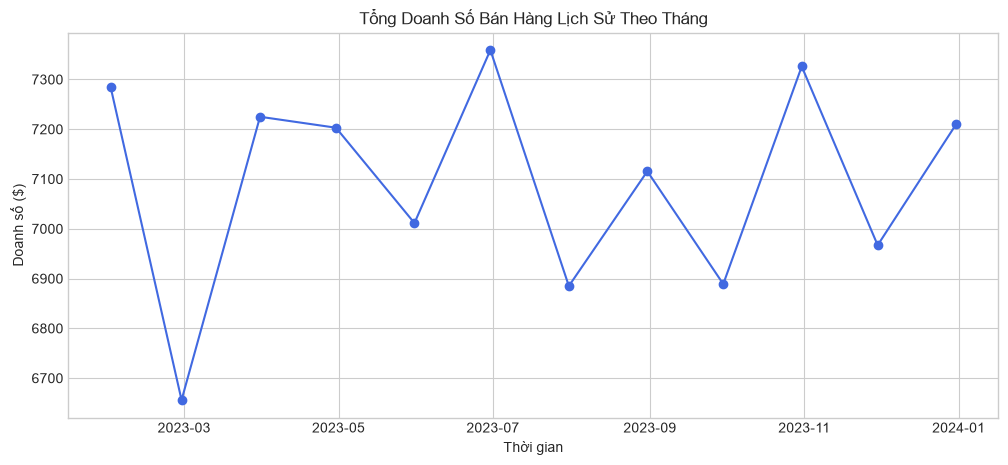

In [3]:
plt.figure(figsize=(12, 5))
plt.plot(ts_data.index, ts_data['sales'], marker='o', linestyle='-', color='royalblue')
plt.title('Tổng Doanh Số Bán Hàng Lịch Sử Theo Tháng')
plt.xlabel('Thời gian')
plt.ylabel('Doanh số ($)')
plt.grid(True)
plt.show()


## 4. Huấn luyện Mô hình Học máy Chuỗi thời gian (Holt-Winters)

In [4]:
# Chia Train/Test (giữ lại 3 tháng cuối để kiểm thử)
test_size = 3
train = ts_data.iloc[:-test_size]
test = ts_data.iloc[-test_size:]

# Khởi tạo mô hình Holt-Winters (Xử lý Trend và Seasonality)
model = ExponentialSmoothing(train['sales'], trend='add', seasonal='add', seasonal_periods=4, initialization_method='estimated').fit()

# Đánh giá trên tập test
predictions = model.forecast(len(test))
mae = mean_absolute_error(test['sales'], predictions)
rmse = np.sqrt(mean_squared_error(test['sales'], predictions))

print('=== ĐÁNH GIÁ MÔ HÌNH TIME SERIES ===')
print(f'MAE (Sai số trung bình): ${mae:.2f}')
print(f'RMSE: ${rmse:.2f}')


=== ĐÁNH GIÁ MÔ HÌNH TIME SERIES ===
MAE (Sai số trung bình): $77.78
RMSE: $91.82


### Đồ thị Lịch sử (Train) vs Thực tế (Test) vs Dự báo (Forecast)

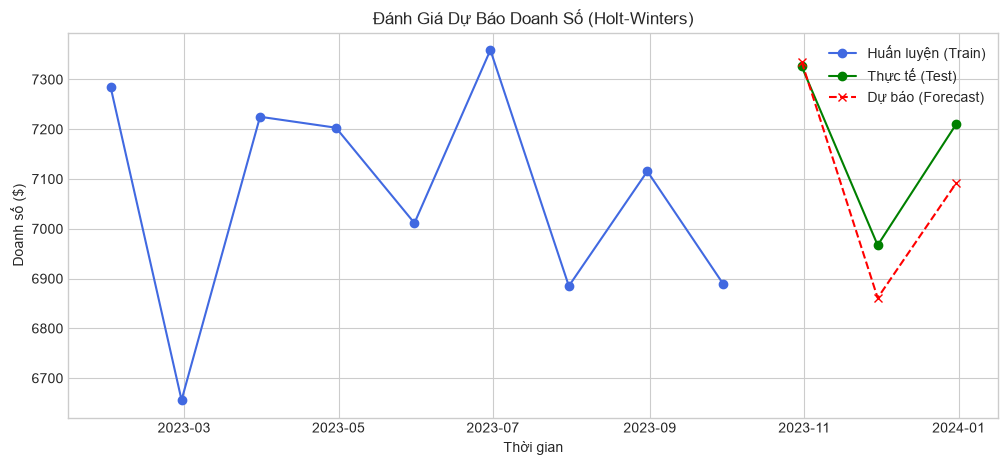

In [5]:
plt.figure(figsize=(12, 5))
plt.plot(train.index, train['sales'], label='Huấn luyện (Train)', color='royalblue', marker='o')
plt.plot(test.index, test['sales'], label='Thực tế (Test)', color='green', marker='o')
plt.plot(test.index, predictions, label='Dự báo (Forecast)', color='red', linestyle='--', marker='x')

plt.title('Đánh Giá Dự Báo Doanh Số (Holt-Winters)')
plt.xlabel('Thời gian')
plt.ylabel('Doanh số ($)')
plt.legend()
plt.grid(True)
plt.show()


## 5. Dự báo Tương lai (Future Forecasting) 3 Tháng Tiếp Theo

In [6]:
# Huấn luyện lại trên toàn bộ dữ liệu lịch sử và dự báo
final_model, metrics = train_forecast_model(df_processed)
forecast_df = forecast_future_sales(final_model, steps=3)
print(forecast_df)


  forecast_date  predicted_sales
0    2024-01-31          7067.50
1    2024-02-29          7119.66
2    2024-03-31          7031.66


## 6. Xuất Dữ Liệu Kết Quả Ra File CSV (Output CSV)
Xuất tập dữ liệu dự báo ra file CSV.

In [7]:
output_file = os.path.join("data", "advanced_forecast_data.csv")
forecast_df.to_csv(output_file, index=False)
print(f"✅ Đã xuất kết quả dự báo ra file: {output_file}")


✅ Đã xuất kết quả dự báo ra file: data/advanced_forecast_data.csv


## 7. Nâng cao Bài 10 & Bài 11: Feature Engineering, Random Forest Regression & Classification
So sánh mô hình nâng cao **Random Forest** với mô hình Baseline.

=== KẾT QUẢ MÔ HÌNH NÂNG CAO (BÀI 10 & BÀI 11) ===
[Bài 10 - Random Forest Regression]     R2 Score = 0.9655, MAE = $0.42
[Bài 11 - Random Forest Classification] Accuracy = 0.8679, F1  = 0.8359


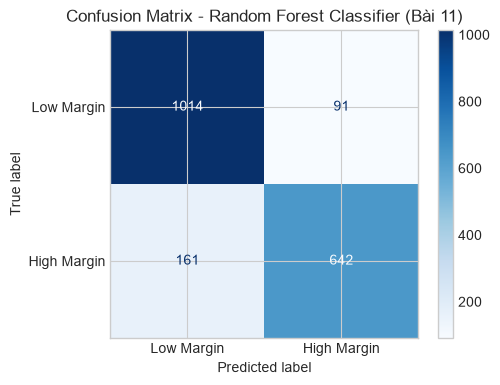

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import r2_score, accuracy_score, f1_score, ConfusionMatrixDisplay
df_processed["discount_amount"] = (df_processed["sales"] * df_processed["discount"]).round(2)
df_processed["is_weekend"] = df_processed["day_of_week"].isin(["Saturday", "Sunday"]).astype(int)
df_processed["is_high_margin"] = (df_processed["profit_margin"] >= 35.0).astype(int)
X_adv = pd.get_dummies(df_processed[["sales", "discount", "discount_amount", "is_weekend", "category"]], drop_first=False)
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(X_adv, df_processed["profit"], test_size=0.2, random_state=42)
rf_reg = RandomForestRegressor(n_estimators=100, max_depth=8, random_state=42).fit(Xr_tr, yr_tr)
yr_pred = rf_reg.predict(Xr_te)
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(X_adv, df_processed["is_high_margin"], test_size=0.2, random_state=42)
rf_clf = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42).fit(Xc_tr, yc_tr)
yc_pred = rf_clf.predict(Xc_te)
print("=== KẾT QUẢ MÔ HÌNH NÂNG CAO (BÀI 10 & BÀI 11) ===")
print(f"[Bài 10 - Random Forest Regression]     R2 Score = {r2_score(yr_te, yr_pred):.4f}, MAE = ${mean_absolute_error(yr_te, yr_pred):.2f}")
print(f"[Bài 11 - Random Forest Classification] Accuracy = {accuracy_score(yc_te, yc_pred):.4f}, F1  = {f1_score(yc_te, yc_pred):.4f}")
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(yc_te, yc_pred, display_labels=["Low Margin", "High Margin"], cmap="Blues", ax=ax)
plt.title("Confusion Matrix - Random Forest Classifier (Bài 11)")
plt.show()
